# F03.05 · Mejorar la red paso a paso: la escalera de mejoras

![Portada del notebook F03.05](img/portada_notebook_05.png)

> 🧭 **En 30 segundos**
> - **Para qué:** la red de F03.04 se queda cerca de XGBoost pero **por debajo**, y se aprende de memoria a los pacientes de 🔵 train en la primera época. Aquí se prueban, **de uno en uno**, cambios para frenarlo, y se va viendo cómo mejora.
> - **Entra:** los mismos datos que F03.04 (los espectros ya calculados), la red de F03.04 como punto de partida y las puntuaciones de XGBoost de F03.03 → **Sale:** la **escalera** (qué cambio se probó, cuánto subió o bajó la AUC en 🟡 dev y si se quedó), la mejor red y su comparación con XGBoost, y un **registro** de todos los experimentos.
> - **Idea clave:** cada **peldaño** cambia **una sola cosa** de la mejor red hasta ese momento. Si la AUC sube, el cambio se queda; si no, se descarta. Así se sabe qué ha ayudado y cuánto.

> 📍 **Dónde estamos: Fase 3 · notebook 5 (F03.05).** F03.04 construyó la primera red (CNN + GRU). Este notebook es **vivo**: para probar algo nuevo basta con añadir una línea a la lista de peldaños (§5) y volver a ejecutarlo; lo ya entrenado se lee del registro.

> 🔄 **Es dinámico.** Lee lo que dejaron F03.01, F03.03 y F03.04; las cifras, las decisiones y las conclusiones salen de los datos al ejecutarlo.

> 🔒 **Regla de oro de la Fase 3: aquí no se mira 🟢 eval.** Todo se decide con 🟡 dev.

| Fase del TFM | | Estado |
|---|---|---|
| Fase 1 | Exploración de datos | ✅ terminada |
| Fase 2 | Preprocesado y ventanas | ✅ terminada |
| **Fase 3** | **Modelo de predicción (⏳ preictal frente a 💤 interictal)** | 👉 **en curso** (la fase de este notebook) |
| Fase 4 | Clasificación de tipos de crisis | pendiente |
| Fase 5 | Explicabilidad (XAI) | pendiente |
| Fase 6 | Memoria | pendiente |
| Fase 7 | Revisión y defensa | pendiente |

## 🧩 La idea, en sencillo

Piensa en ajustar una receta: si cambias a la vez la sal, el horno y el tiempo y sale mejor, no sabes qué lo ha arreglado. Si cambias **una cosa cada vez** y la pruebas, sabes qué ayuda y qué no.

![La escalera de mejoras](img/escalera_mejoras.png)

👀 **Qué enseña.** (Las cifras son un ejemplo.) Cada barra es un peldaño: un cambio probado sobre la mejor red hasta ese momento. Si su AUC sube, el cambio **se queda** (rojo) y el siguiente se prueba encima; si no, **se descarta** (gris) y el siguiente se prueba sobre la anterior. La línea discontinua es XGBoost de F03.03. A la derecha, el **registro**: lo ya entrenado no se repite.

| Pregunta | Dónde se responde |
|---|---|
| ¿Qué cambios frenan el sobreajuste y cuánto ayuda cada uno? | §6 y §7 (la escalera) |
| ¿La mejor red supera ya a XGBoost, en la nota global y **dentro de cada paciente**? | §8 (recuadro dorado) |
| ¿Funciona en la mayoría de pacientes y aguanta el control de sesión? | §9 |

![La historia de la Fase 3, con F03.05 destacado](img/historia_fase_03_nb05.png)

👀 **Qué enseña.** Las preguntas de toda la fase, en orden, y lo que salió. El recuadro rojo marca **dónde estás**; el resto de la fase sale atenuado.

## El recorrido de este notebook

![El recorrido del notebook F03.05](img/mapa_notebook_05.png)

👀 **Qué enseña.** Los seis pasos. Los tres en rojo son los importantes: **subir la escalera** (§6), **ver cómo mejora** (§7) y **compararla con XGBoost** (§8-§9).

### 📖 Diccionario rápido

| Término | Qué significa, en sencillo |
|---|---|
| **Peldaño** | Un experimento: la mejor red hasta ahora con **un** cambio. Se entrena con 3 semillas y se mide en 🟡 dev |
| **Sobreajuste** | Aprenderse los ejemplos de train (aquí, los pacientes) en vez de la regla: train mejora y dev empeora (F03.04 §7) |
| **Regularizar** | Cualquier cosa que le pone difícil a la red memorizar: red más pequeña, más dropout, aumentos, pasos más cortos |
| **Huella** | 10 letras que identifican una configuración. Si ya está en el registro (con las mismas ventanas), no se vuelve a entrenar |
| **Registro** | La lista de todos los experimentos hechos, con su configuración y su nota (`registro/registro.csv`) |
| **Tasa de aprendizaje** | Lo grande que es cada paso al corregir los pesos. Más pequeña = aprende más despacio pero con más cuidado |
| **Aumento de datos** | Variar los ejemplos al entrenar (apagar un canal, tapar unas frecuencias...) para que la red no dependa de un detalle |
| **Diferencia emparejada** | Comparar dos modelos con las mismas ventanas y los mismos sorteos de pacientes (F03.03 §9) |
| **AUC dentro del paciente** | Como la AUC, pero comparando solo ventanas **del mismo paciente**: ¿la ⏳ de un paciente sale más alta que sus propias 💤? Es lo que necesita una app, que vigila siempre a la misma persona. Ver §2 |
| **IC 95 %** | El margen de error de una cifra: dónde estaría con otros pacientes parecidos (bootstrap por paciente) |

## 0. Los parámetros

> 🎯 **Qué hacemos:** elegir el conjunto, si se hace una prueba rápida y si se reentrena todo.
>
> 🤔 **Por qué:** el registro guarda cada peldaño: sin `REENTRENAR`, solo se entrena lo que falta.

- `CONJUNTO`: `general` (o `grupo_ausencia`, tras ejecutar F03.01-F03.04 con él).
- `MODO_PRUEBA`: `True` para comprobar que todo funciona en pocos minutos (el 10 % de las ventanas, 1 semilla, 2 épocas). Los resultados van a una carpeta aparte, `_prueba`.
- `REENTRENAR`: `True` para volver a entrenar todos los peldaños aunque estén en el registro.

*(La celda lleva la etiqueta `parameters` para poder lanzarla con papermill.)*

> **`CONJUNTO` se fija en un solo sitio para toda la Fase 3:** `tfm_comun/prediccion/estudio.py` (`CONJUNTO_ESTUDIO`). Aquí se deja en `None`; solo se pone otro valor para una prueba puntual (o desde papermill). Los resultados de cada conjunto van a su carpeta: `outputs/fase_03/<conjunto>/`.

In [16]:
CONJUNTO = None   # None = el de tfm_comun/prediccion/estudio.py (el mismo en toda la Fase 3); se puede poner otro aquí
MODO_PRUEBA = False
REENTRENAR = False

Failed to reload module 'tfm_comun.red.entrenamiento' from file 'D:\Dani\TFM IA\03.Codigo\ALMA\tfm_comun\red\entrenamiento.py'
Traceback (most recent call last):
  File "D:\Dani\TFM IA\03.Codigo\ALMA\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 326, in check
    superreload(m, reload, self.old_objects)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\Dani\TFM IA\03.Codigo\ALMA\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 580, in superreload
    module = reload(module)
  File "C:\Users\Usuario\AppData\Local\Programs\Python\Python314\Lib\importlib\__init__.py", line 129, in reload
    _bootstrap._exec(spec, module)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 869, in _exec
  File "<frozen importlib._bootstrap_external>", line 762, in exec_module
  File "<frozen importlib._bootstrap>", line 491, in _call_with_frames_removed
  File "D:\Dani\TFM IA\03.Codigo\ALMA\tfm_comun\red\entrenamiento.py", line 47, in <mod

## 1. Librerías

> 🎯 **Qué hacemos:** comprobar las librerías (PyTorch con GPU entre ellas) y cargar las de `tfm_comun/red/`.
>
> 🤔 **Por qué:** son las mismas piezas que F03.04: arquitectura, entrenamiento y evaluación.

In [17]:
# Requisitos: se comprueba (e instala si falta) lo que necesita el notebook ANTES de importar nada más
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
from tfm_comun.entorno.requisitos import comprobar_requisitos, REQUISITOS_FASE_03_RED
disponibles = comprobar_requisitos(REQUISITOS_FASE_03_RED)

,estado,versión,para qué
librería,,,
numpy,✅,2.5.4,cálculo con matrices
pandas,✅,3.0.6,tablas
matplotlib,✅,3.11.2,figuras
scipy,✅,1.18.1,espectro de cada ventana (Welch)
scikit-learn,✅,1.9.1,"regresión logística, AUROC y curvas ROC"
xgboost,✅,3.4.1,XGBoost: árboles de decisión encadenados
joblib,✅,1.6.0,guardar los modelos entrenados
tqdm,✅,4.70.1,barra de progreso al calcular las características
torch,✅,2.15.0+cu132,"la red neuronal: capas, entrenamiento en la GPU (PyTorch)"


Todo lo necesario está instalado.


In [ ]:
# 1) Recarga automática: si cambia un módulo de tfm_comun, se vuelve a cargar solo (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2

# 2) Vuelve a leer tfm_comun del disco cada vez que se ejecuta esta celda (por si ha cambiado)
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

# 3) Librerías de siempre
import copy
import json
from functools import partial
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import torch
from scipy.stats import rankdata
from tqdm.auto import tqdm
from IPython.display import display, Markdown

# 4) tfm_comun: entorno, red, entrenamiento y evaluación
from tfm_comun.entorno.rutas import RUTA_OUTPUTS_FASE_03, carpeta_resultados
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.entorno.dispositivo import elegir_dispositivo
from tfm_comun.entorno.configuracion import leer_configuracion
from tfm_comun.red.preparacion import preparar_datos_red
from tfm_comun.red.redes.cnn_gru import ARQUITECTURA
from tfm_comun.red.modelo import crear_red, contar_parametros
from tfm_comun.red.entreno.entrenar_red import ENTRENAMIENTO
from tfm_comun.red.experimentos.registro import Registro
from tfm_comun.red.entreno.variantes import EntrenadorVariantes
from tfm_comun.prediccion.evaluacion.auroc_global import auroc_con_intervalo
from tfm_comun.prediccion.evaluacion.auroc_paciente import auroc_por_paciente, auroc_dentro_paciente
from tfm_comun.prediccion.control_sesion import controles_de_sesion
from tfm_comun.prediccion.evaluacion.evaluador import Evaluador
from tfm_comun.prediccion.evaluacion.lectura import lectura_diferencia

# 5) tfm_comun: cómo se enseñan las cosas (iconos, colores, números, tablas, ficheros, letra)
from tfm_comun.visual.iconos import con_icono
from tfm_comun.visual.colores import COLORES_ESQUEMA
from tfm_comun.visual.numeros import numero_legible, decimal, con_intervalo, con_signo
from tfm_comun.visual.tablas import con_separadores, mostrar_destacado
from tfm_comun.visual.ficheros import mostrar_fichero
from tfm_comun.visual.tipografia import ESTILO_TIMES

In [ ]:
# 1) Versiones de las librerías
versiones_usadas = mostrar_versiones(np, pd, matplotlib, scipy, sklearn, torch)

# 2) El conjunto: si la celda de parámetros lo deja en None, el de tfm_comun/prediccion/estudio.py
from tfm_comun.prediccion.estudio import conjunto_del_estudio
CONJUNTO = conjunto_del_estudio(CONJUNTO)

✅ **Qué deberías ver:** en la tabla de librerías, todas con ✅ (o 🆕 si se acaban de instalar), y debajo la versión de cada una.

## 2. Configuración

> 🎯 **Qué hacemos:** fijar los "botones" del notebook y leer lo que dejaron F03.01, F03.03 y F03.04.

| Parámetro | Valor | Qué controla |
|---|---|---|
| `N_SEMILLAS` | 3 | Cada peldaño se entrena 3 veces y se promedian las puntuaciones (como en F03.04) |
| `METRICA_ESCALERA` | `'dentro_paciente'` | Con qué nota decide la escalera si un cambio se queda: `'dentro_paciente'` (la AUC dentro del paciente, ver abajo) o `'global'` (la AUC de siempre). Las dos se muestran siempre |
| `MEJORA_PELDANO` | 0,005 | Cuánto tiene que subir esa nota en dev para que un cambio se quede. Pequeño a propósito: cada peldaño es un paso; lo que se mide con intervalo es la escalera entera frente al punto de partida y frente a XGBoost (§8) |
| `ESPECIFICIDAD`, `N_BOOTSTRAP`, `MEJORA_MINIMA` | 0,9 · 500 · 0,02 | Como en F03.03 y F03.04 |

### Por qué la escalera decide con la AUC dentro del paciente

![La AUC global frente a la AUC dentro del paciente](img/auc_dentro_paciente.png)

👀 **Qué enseña.** Dos pacientes. La AUC global compara **todas** las ⏳ con **todas** las 💤, también de pacientes distintos: un modelo que puntúa más alto todo lo del paciente A (que tiene más ⏳) gana nota sin distinguir nada **dentro** de cada uno. La AUC dentro del paciente solo compara ⏳ y 💤 **del mismo paciente**, que es lo que haría una app.

En la primera ejecución de este notebook, la mejor red superó a XGBoost en la AUC global pero no dentro del paciente (las cifras de cada ejecución están en §8): parte de su nota venía de separar pacientes. Por eso la escalera decide con la nota dentro del paciente, y hay un peldaño que hace que la propia red elija su mejor época con ella.

In [19]:
N_SEMILLAS = 3
METRICA_ESCALERA = 'dentro_paciente'
MEJORA_PELDANO = 0.005
ESPECIFICIDAD = 0.9
N_BOOTSTRAP = 500
MEJORA_MINIMA = 0.02

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = modelo principal) <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code> · <code>True</code> = prueba rápida (pocas ventanas, 1 semilla); las cifras no valen <i style="color:#4d4d4d">(§0)</i></li></ul></div>

In [20]:
# 1) Carpetas de resultados y modelos, y el registro de experimentos
SUFIJO = '_prueba' if MODO_PRUEBA else ''
RUTA_RESULTADOS, RUTA_FIGURAS = carpeta_resultados(f'fase_03/{CONJUNTO}/05_mejoras_red' + SUFIJO)
RUTA_MODELOS = RUTA_RESULTADOS / 'modelos'
RUTA_MODELOS.mkdir(exist_ok=True)
registro = Registro(RUTA_RESULTADOS / 'registro')

# 2) leer_config: el configuracion.json de un notebook anterior, comprobando que es de este CONJUNTO
# (tfm_comun/entorno/configuracion.py; para con un mensaje claro si falta o es de otro conjunto)
leer_config = partial(leer_configuracion, conjunto=CONJUNTO, pista=' y MODO_PRUEBA = True' if MODO_PRUEBA else '')
config_01 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '01_datos_red' / 'configuracion.json', 'F03.01 (fase_03/01_datos_red.ipynb)')
config_03 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '03_contexto_y_paciente' / 'configuracion.json', 'F03.03 (fase_03/03_contexto_y_paciente.ipynb)')
config_04 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / ('04_red_prediccion' + SUFIJO) / 'configuracion.json', 'F03.04 (fase_03/04_red_prediccion.ipynb)')

# 3) Semillas y nombre del modelo a superar
if MODO_PRUEBA:
    N_SEMILLAS = 1
SEMILLAS = [int(config_01['semilla']) + s for s in range(N_SEMILLAS)]
NOMBRE_XGB = f'XGBoost F03.03 ({config_03["mejor"]["contexto_s"]} s, {config_03["mejor"]["normalizacion"]})'

# 4) Dónde se entrena (GPU o procesador)
dispositivo, ficha = elegir_dispositivo()

# 5) Resumen
print(f'Conjunto: {CONJUNTO}{" · 🔴 MODO PRUEBA (cifras sin valor)" if MODO_PRUEBA else ""} · semillas: {SEMILLAS}')
print(f'Dispositivo: {ficha["dispositivo"]} · {ficha["nombre"]}' + (f' · {ficha["memoria (GB)"]} GB' if ficha['memoria (GB)'] else ''))
print(f'Punto de partida (F03.04): red {config_04["principal"]["variante"]} → AUC {decimal(config_04["principal"]["auc_dev"])} · '
      f'a superar: {NOMBRE_XGB} → AUC {decimal(config_04["frente_a_xgboost"]["auc_xgboost"])}')

Conjunto: general · semillas: [42, 43, 44]
Dispositivo: cuda (GPU NVIDIA) · NVIDIA GeForce RTX 3060 · 12.9 GB
Punto de partida (F03.04): red red_60s → AUC 0,66 · a superar: XGBoost F03.03 (60 s, por_paciente_calibrado) → AUC 0,71


## 3. Los datos: los mismos de F03.04

> 🎯 **Qué hacemos:** preparar exactamente los datos de F03.04 (§3-§5 de allí) con una sola función, `preparar_datos_red` (`tfm_comun/red/preparacion.py`): las mismas filas, los mismos espectros (ya calculados: tarda segundos) y la misma calibración por paciente.
>
> 🤔 **Por qué una función:** así todos los notebooks de la red usan los mismos datos sin copiar código. F03.04 explica cada paso con figuras; aquí solo se comprueba que todo coincide.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = modelo principal) <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code> · <code>True</code> = prueba rápida (pocas ventanas, 1 semilla); las cifras no valen <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">config_01</code> · configuración de F03.01 (semilla, ventanas) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">config_03</code> · configuración de F03.03 (la decisión para la red) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">config_04</code> · configuración de F03.04 (la red y su nota) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">dispositivo</code> · dónde se entrena: la GPU si la hay, si no la CPU <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [21]:
# 1) Preparar los datos de la red (los mismos que F03.04): ventanas, etiquetas, rondas y espectros
inicio = time.time()
red_datos = preparar_datos_red(CONJUNTO, config_01, config_03, dispositivo, modo_prueba=MODO_PRUEBA,
                               progreso=lambda it, total: tqdm(it, total=total, desc='tramos de F02.02 leídos'))
filas, y, pacientes, rondas, validar, datos = (red_datos.filas, red_datos.y, red_datos.pacientes, red_datos.rondas,
                                               red_datos.validar, red_datos.datos)
FS, K = red_datos.fs, red_datos.k
ids_validacion = filas.id_ventana.to_numpy()[validar]

# 2) Tabla de los datos
tabla_datos = pd.DataFrame({'filas': [len(filas)], 'entrenamiento': [int(filas.en_entrenamiento.sum())], 'validación': [int(validar.sum())],
                            'pacientes': [len(set(pacientes))], 'ventanas por secuencia': [K], 'espectros': [red_datos.estado_almacen],
                            'en': ['GPU' if datos.en_dispositivo and dispositivo.type != 'cpu' else 'memoria'],
                            'minutos': [(time.time() - inicio) / 60]}, index=[CONJUNTO])
tabla_datos.index.name = 'conjunto'
display(con_separadores(tabla_datos, decimales=1))

# 3) ¿Las mismas ventanas de validación que F03.04?
iguales = config_04['ventanas_comparadas'] == int(validar.sum())
print('✅ Las mismas ventanas de validación que F03.04.' if iguales else
      f'🔴 F03.04 comparó {numero_legible(config_04["ventanas_comparadas"])} ventanas y aquí hay {numero_legible(int(validar.sum()))}: ¿ha cambiado algo antes?')

# 4) Las puntuaciones de XGBoost de F03.03 en las mismas ventanas (para §8-§9)
puntos_03 = pd.read_csv(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '03_contexto_y_paciente' / 'puntuaciones_validacion.csv').set_index('id_ventana')
comun = validar & filas.id_ventana.isin(puntos_03.index).to_numpy()
p_xgb = np.full(len(filas), np.nan)
p_xgb[comun] = puntos_03.loc[filas.id_ventana[comun], 'puntuacion_mejor'].to_numpy()

,filas,entrenamiento,validación,pacientes,ventanas por secuencia,espectros,en,minutos
conjunto,,,,,,,,
general,89.149,34.401,54.748,120,15,ya estaba al día,GPU,"0,6"


✅ Las mismas ventanas de validación que F03.04.


👀 **Cómo leer la tabla.** Cuántas filas, de entrenamiento y de validación, de cuántos pacientes, cuántas ventanas tiene cada secuencia y si los espectros se han leído del almacén (*ya estaba al día*) o se han calculado.

✅ **Qué deberías ver:** *ya estaba al día* y el ✅ de abajo: son exactamente los datos de F03.04.

## 4. El punto de partida: por qué la red de F03.04 se aprende a los pacientes

> 🎯 **Qué hacemos:** recordar, con los datos que dejó F03.04, cuándo salía su mejor red y cuánto bajaba la pérdida de train.

![Por qué la red se aprende las secuencias de memoria](img/secuencias_repetidas.png)

👀 **Qué enseña.** Arriba, un tramo ⏳ y tres filas seguidas: sus secuencias de 60 s se solapan casi enteras. Abajo a la izquierda, lo que pasaba en F03.04; a la derecha, el peldaño que lo ataca de frente: en cada época, una sola fila de cada trozo de 16 s.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = modelo principal) <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SUFIJO</code> · <code>_prueba</code> en los ficheros si es una prueba <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [22]:
# 1) El historial de entrenamiento de F03.04
historial_04 = pd.read_csv(RUTA_OUTPUTS_FASE_03 / CONJUNTO / ('04_red_prediccion' + SUFIJO) / 'historial_entrenamiento.csv')

# 2) Por variante: mejor época, pérdida al final y AUC en dev
filas_04 = []
for variante, h in historial_04.groupby('variante', sort=False):
    mejores = h.loc[h.groupby('semilla')['AUC validación'].idxmax()]
    filas_04.append({'variante (F03.04)': variante, 'mejor época (por semilla)': ' · '.join(str(int(e)) for e in mejores['época']),
                     'pérdida train al final': h.groupby('semilla')['pérdida train'].last().mean(),
                     'AUC dev en la mejor época': mejores['AUC validación'].mean(),
                     'AUC dev al final': h.groupby('semilla')['AUC validación'].last().mean()})

# 3) Tabla
tabla_04 = pd.DataFrame(filas_04).set_index('variante (F03.04)')
display(con_separadores(tabla_04, decimales=3))

,mejor época (por semilla),pérdida train al final,AUC dev en la mejor época,AUC dev al final
variante (F03.04),,,,
red_60s,1 · 4 · 1,"0,051","0,634","0,569"
red_4s,1 · 2 · 2,"0,385","0,658","0,572"
red_60s_mismo_peso,1 · 1 · 1,"0,070","0,679","0,616"


👀 **Cómo leer la tabla.** Para cada red de F03.04: en qué época salió su mejor AUC (una cifra por semilla), cuánto llegó a bajar la pérdida de train y cuánto perdía la AUC de dev desde su mejor momento hasta el final.

✅ **Qué deberías ver:** mejores épocas de 1 o 2 y una pérdida de train muy baja al final (muy por debajo de la del principio): la red se aprende los ejemplos de train y empeora en dev. Es lo que intentan arreglar los peldaños.

## 5. Los peldaños: qué se prueba y por qué

> 🎯 **Qué hacemos:** escribir la lista de cambios, en el orden en que se prueban. Cada uno se aplica sobre **la mejor red hasta ese momento**.
>
> ➕ **Para probar algo nuevo:** añade una línea al final de `PELDANOS` con su nombre, el cambio y el porqué, y vuelve a ejecutar el notebook. Solo se entrena lo nuevo.

![Dos aumentos del espectro](img/aumentos_espectro.png)

👀 **Qué enseña.** Los dos aumentos del peldaño 5: apagar canales enteros (como un electrodo que falla) y tapar una franja de frecuencias. Solo al entrenar.

**Qué se puede cambiar en cada peldaño** (todo tiene su explicación en `tfm_comun/red/`):

| Clave | Qué cambia | Dónde |
|---|---|---|
| `arquitectura` | `filtros`, `resumen_ventana`, `memoria_gru`, `dropout` | `redes/cnn_gru.py` |
| `entrenamiento` | `lr`, `weight_decay`, `epocas_max`, `paciencia`, `tamano_lote`, `reflejo`, `evaluaciones_por_epoca`, `apagar_canales`, `tapar_frecuencias`, `equilibrar_clases` | `entrenamiento.py` |
| `separacion_s` | de cada trozo de tantos segundos de un tramo, una fila por época (0 = todas) | `secuencias.py` |
| `mismo_peso` | cada paciente sale las mismas veces en cada época | `secuencias.py` |
| `entrenamiento: criterio` | `'auc_global'` o `'auc_dentro_paciente'`: con qué nota elige la red su mejor época | `entrenamiento.py` |
| `mezclar_xgboost` | no entrena nada: junta la mejor red con XGBoost de F03.03 (media de rangos) | este notebook |

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">K</code> · ventanas de 4 s de cada secuencia <i style="color:#4d4d4d">(§3)</i></li></ul></div>

In [ ]:
# 1) El punto de partida: la red principal de F03.04
PUNTO_DE_PARTIDA = {'arquitectura': dict(ARQUITECTURA), 'entrenamiento': dict(ENTRENAMIENTO), 'separacion_s': 0, 'mismo_peso': False, 'k': K}

# 2) Los peldaños: (nombre, cambio, por qué), un cambio cada uno
PELDANOS = [
    ('evaluar_a_menudo', {'entrenamiento': {'evaluaciones_por_epoca': 4}},
     'La mejor red salía en la época 1: midiendo cada cuarto de época no se pierde el mejor punto, aunque esté a mitad de la primera.'),
    ('tasa_menor', {'entrenamiento': {'lr': 1e-4}},
     'Pasos 10 veces más pequeños: la red tarda más en memorizar y el mejor punto llega más tarde y con más cuidado.'),
    ('red_pequena', {'arquitectura': {'filtros': 16, 'resumen_ventana': 32, 'memoria_gru': 32, 'dropout': 0.5}},
     'Unas 4 veces menos parámetros y más dropout: menos capacidad para aprenderse a los pacientes de memoria.'),
    ('sin_repetidas', {'separacion_s': 16, 'entrenamiento': {'equilibrar_clases': True, 'epocas_max': 80}},
     'En cada época, una sola fila de cada trozo de 16 s: no hay secuencias casi iguales en la misma época. Como quedan más 💤 '
     'que ⏳, las clases se equilibran en la pérdida; y como cada época es más corta, se permiten más épocas.'),
    ('aumentos', {'entrenamiento': {'apagar_canales': 0.1, 'tapar_frecuencias': 4}},
     'Apagar canales y tapar frecuencias al azar: la red no puede apoyarse en un canal o una frecuencia concretos de un paciente.'),
    ('mismo_peso', {'mismo_peso': True},
     'En F03.04 fue la variante con mejor AUC global (aunque peor dentro de cada paciente): se prueba sobre la mejor red hasta ahora.'),
    ('criterio_dentro_paciente', {'entrenamiento': {'criterio': 'auc_dentro_paciente'}},
     'La parada temprana elegía la época con la AUC global, que premia separar pacientes. Con la AUC dentro del paciente elige '
     'la época que mejor ordena los momentos de cada persona.'),
    ('mezcla_xgboost', {'mezclar_xgboost': True},
     'La red y XGBoost aciertan en ventanas distintas (sus puntuaciones se parecen poco). Sin entrenar nada: la media de sus rangos. '
     'Si se queda, la evaluación final necesitará también XGBoost de F03.03.'),
    # ⚠️ La mezcla va siempre la ÚLTIMA: no entrena nada, así que un peldaño de entrenamiento detrás de ella no tendría efecto.
]

➡️ **Paso 2.** Se define `combinar`.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code> · <code>True</code> = prueba rápida (pocas ventanas, 1 semilla); las cifras no valen <i style="color:#4d4d4d">(§0)</i></li></ul></div>

In [ ]:
# 1) Combinar la configuración base con los cambios de un peldaño
def combinar(base, cambios):
    """La configuración base con los cambios encima (los diccionarios se combinan clave a clave)."""
    nueva = copy.deepcopy(base)
    for clave, valor in cambios.items():
        if isinstance(valor, dict):
            nueva[clave] = {**nueva.get(clave, {}), **valor}
        else:
            nueva[clave] = valor
    if MODO_PRUEBA:
        nueva['entrenamiento']['epocas_max'] = 2
    return nueva

# 2) Describir un cambio en texto
def describir(cambios):   # {'entrenamiento': {'lr': 0.0001}} -> 'lr = 0.0001'
    partes = []
    for clave, valor in cambios.items():
        partes += [f'{k} = {v}' for k, v in valor.items()] if isinstance(valor, dict) else [f'{clave} = {valor}']
    return ' · '.join(partes)

# 3) Tabla de los peldaños
tabla_peldanos = pd.DataFrame([{'peldaño': f'{i} · {n}', 'cambio': describir(c), 'por qué': p} for i, (n, c, p) in enumerate(PELDANOS, start=1)]).set_index('peldaño')
display(tabla_peldanos.style.set_properties(**{'text-align': 'left'}))

👀 **Cómo leer la tabla.** Un peldaño por fila, en el orden en que se prueban: qué cambia (respecto a la mejor red hasta ese momento) y por qué se espera que ayude.

> 💡 El orden importa: un cambio puede ayudar solo si antes se ha hecho otro. Se empieza por lo más barato y directo (medir más a menudo) y se acaba por lo que cambia qué ve la red (aumentos, peso por paciente).

✅ **Qué deberías ver:** un cambio por fila, de lo más barato a lo que cambia qué ve la red.

## 6. Subir la escalera

> 🎯 **Qué hacemos:** entrenar el punto de partida y cada peldaño con 3 semillas, medirlos en 🟡 dev y decidir si el cambio se queda. Lo que ya está en el registro (misma configuración, mismas ventanas) se lee en vez de entrenarse.
>
> 🤔 **Por qué se vuelve a entrenar el punto de partida:** con el mismo código que los peldaños, para que la comparación sea limpia. Debería salir igual que en F03.04 (se comprueba en la tabla).

> 💡 Con GPU, cada peldaño tarda de **1 a 10 minutos** (los que miden más a menudo o tienen la tasa de aprendizaje baja tardan más). La segunda vez, segundos.

> 🧱 **Cómo está hecho el código (nuevo).** Entrenar un peldaño (3 semillas, leer del registro si ya está, guardar cada entrenamiento suelto y los puntos de control) lo hace `EntrenadorVariantes` (`tfm_comun/red/entreno/variantes.py`); medirlo, `Evaluador` (`tfm_comun/prediccion/evaluacion/evaluador.py`). Antes F03.05-F03.08 copiaban esas funciones en cada notebook: ahora están una sola vez y el notebook solo dice **qué** se prueba.

![Entrenar una variante](img/entrenar_una_variante.png)


<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§0:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">REENTRENAR</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§2:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">METRICA_ESCALERA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_MODELOS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_RESULTADOS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLAS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">dispositivo</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">registro</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§3:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comun</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_xgb</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">red_datos</code></li></ul></div>

In [ ]:
# 1) Entrenar (o leer del registro) cada peldaño: tfm_comun/red/entreno/variantes.py (sin 'notebook' en la huella, como siempre en F03.05)
entrenador = EntrenadorVariantes(red_datos, dispositivo, registro, RUTA_MODELOS, SEMILLAS, CONJUNTO, MODO_PRUEBA,
                                 reentrenar=REENTRENAR, carpeta_puntos_control=RUTA_RESULTADOS / 'puntos_control',
                                 nombre_en_modelo='peldaño', barra=lambda iterable, texto: tqdm(iterable, desc=texto, leave=False))

# 2) Un peldaño: entrenar, o mezclar con XGBoost (sin entrenar)
def entrenar_configuracion(nombre, config):
    """Un peldaño: (huella, puntuaciones (semillas, filas), historial, estado, minutos). La mezcla con XGBoost no entrena nada."""
    if config.get('mezclar_xgboost'):                       # la red de la que sale + XGBoost, sin entrenar
        P = np.full((len(SEMILLAS), len(filas)), np.nan)
        P[:, comun] = mezclar(actual['p'], p_xgb)[comun]
        return entrenador.huella(config), P, actual['historial'], 'mezcla (sin entrenar)', 0.0
    return entrenador.entrenar(nombre, config)

# 3) La mezcla: media de los rangos
def mezclar(a, b):
    """La media de los rangos (de 0 a 1) de dos puntuaciones, en las ventanas comunes."""
    salida = np.full(len(filas), np.nan)
    salida[comun] = (rankdata(a[comun]) + rankdata(b[comun])) / (2 * comun.sum())
    return salida

# 4) La nota con la que decide la escalera
NOTA = {'global': 'AUC-ROC', 'dentro_paciente': 'AUC dentro del paciente'}[METRICA_ESCALERA]

➡️ **Paso 2.** Las notas de cada modelo, siempre con las mismas ventanas de 🟡 dev (comun) y los mismos sorteos de pacientes.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">ESPECIFICIDAD</code> · especificidad a la que se mide la sensibilidad <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">METRICA_ESCALERA</code> · nota que decide la escalera (dentro del paciente) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code> · repeticiones del bootstrap por paciente <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLAS</code> · semillas con las que se entrena cada peldaño <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comun</code> · ventanas de dev que tienen nota de todos los modelos <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · ventanas del estudio (las de F03.03, con contexto completo) <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">validar</code> · qué ventanas se examinan en 🟡 dev <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · etiqueta de cada ventana (1 = ⏳ preictal) <i style="color:#4d4d4d">(§3)</i></li></ul></div>

In [ ]:
# 1) Las notas de cada modelo, siempre con las mismas ventanas de 🟡 dev (comun) y los mismos sorteos de pacientes
# (tfm_comun/prediccion/evaluacion/evaluador.py)
evaluador = Evaluador(y, pacientes, comun, especificidad=ESPECIFICIDAD, n_bootstrap=N_BOOTSTRAP, semilla=SEMILLAS[0])

# 2) Diferencia emparejada con la nota de la escalera
def diferencia(a, b):
    """Diferencia emparejada (a - b) con la nota que usa la escalera."""
    return evaluador.diferencia(a, b, dentro=METRICA_ESCALERA == 'dentro_paciente')

# 3) Media de las semillas
def media_semillas(P):
    p = np.full(len(filas), np.nan)
    p[validar] = P[:, validar].mean(axis=0)
    return p

# 4) La nota de cada semilla
def auc_por_semilla(P):
    if METRICA_ESCALERA == 'dentro_paciente':
        return [auroc_dentro_paciente(y[comun], fila[comun], pacientes[comun]) for fila in P]
    return [float(auroc_con_intervalo(y[comun], fila[comun], pacientes[comun], n_bootstrap=1)[0]) for fila in P]

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · conjunto de ventanas de la Fase 3 (<code>general</code> = modelo principal) <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MEJORA_PELDANO</code> · mejora mínima para quedarse con un peldaño <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">PELDANOS</code> · los peldaños: un cambio cada uno <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">PUNTO_DE_PARTIDA</code> · la red de F03.04, de la que se parte <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLAS</code> · semillas con las que se entrena cada peldaño <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">combinar</code> · función: aplica los cambios de un peldaño a la configuración <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">config_04</code> · configuración de F03.04 (la red y su nota) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">describir</code> · función: escribe un cambio en una línea <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">ids_validacion</code> · identificador de cada ventana de dev <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">red_datos</code> · los datos de la red listos para servir lotes <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">registro</code> · registro de experimentos: lo ya entrenado no se repite <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">validar</code> · qué ventanas se examinan en 🟡 dev <i style="color:#4d4d4d">(§3)</i></li></ul></div>

In [ ]:
# 1) Subir la escalera: cada peldaño se prueba sobre la mejor red hasta ahora
escalera, puntuaciones, historiales = [], {}, {}
inicio_total = time.time()
for i, (nombre, cambios, porque) in enumerate([('punto_de_partida', {}, 'la red principal de F03.04')] + PELDANOS):
    base = PUNTO_DE_PARTIDA if i == 0 else actual['config']
    config = combinar(base, cambios)
    h, P, historial, estado, minutos = entrenar_configuracion(nombre, config)
    p = media_semillas(P)
    notas = evaluador.notas(p)
    puntuaciones[nombre], historiales[nombre] = p, historial
    if i == 0:
        decision, dif = 'punto de partida', (np.nan, np.nan, np.nan)
        actual = {'nombre': nombre, 'config': config, 'p': p, 'auc': notas[NOTA], 'huella': h, 'historial': historial}
    else:
        dif = diferencia(p, actual['p'])
        se_queda = notas[NOTA] - actual['auc'] >= MEJORA_PELDANO
        decision = '✅ se queda' if se_queda else '✖️ se descarta'
        sobre = actual['nombre']
        if se_queda:
            actual = {'nombre': nombre, 'config': config, 'p': p, 'auc': notas[NOTA], 'huella': h, 'historial': historial}

    # 2) Su fila de la tabla y su registro
    columna_criterio = ('AUC dentro paciente' if config['entrenamiento'].get('criterio') == 'auc_dentro_paciente' and 'AUC dentro paciente' in historial
                        else 'AUC validación')
    mejores_epocas = historial.loc[historial.groupby(['semilla', 'ronda'])[columna_criterio].idxmax(), 'época']
    parametros = contar_parametros(crear_red(red_datos.n_canales, len(red_datos.frecuencias), config['arquitectura']))['total']
    fila = {'peldaño': f'{i} · {nombre}', 'cambio': describir(cambios) if cambios else '—', 'se prueba sobre': '—' if i == 0 else sobre,
            **notas, f'{NOTA} de cada semilla': ' · '.join(decimal(a) for a in auc_por_semilla(P)),
            'frente a la mejor hasta ahora': '—' if i == 0 else f'{con_signo(dif[0])} [{decimal(dif[1], 3)} – {decimal(dif[2], 3)}]',
            'decisión': decision, 'mejor época (media)': float(mejores_epocas.mean()), 'parámetros': int(parametros),
            'huella': h, 'estado': estado, 'minutos': minutos}
    escalera.append(fila)
    registro.guardar(h, {'nombre': nombre, 'fecha': time.strftime('%Y-%m-%d %H:%M'), 'conjunto': CONJUNTO, 'auc_dev': notas['AUC-ROC'],
                         'ic95': f'{decimal(notas["_inferior"], 3)} – {decimal(notas["_superior"], 3)}',
                         'auc_dentro_paciente': notas['AUC dentro del paciente'],
                         'auc_por_paciente_mediana': notas['AUC por paciente (mediana)'], 'semillas': len(SEMILLAS),
                         'configuracion': json.dumps(config, ensure_ascii=False)},
                     P[:, validar], ids_validacion, historial)

# 3) Tabla de la escalera y resumen
escalera = pd.DataFrame(escalera).set_index('peldaño')
columnas_ver = ['cambio', 'se prueba sobre', 'AUC dentro del paciente', 'AUC-ROC', f'{NOTA} de cada semilla', 'frente a la mejor hasta ahora',
                'decisión', 'AUC por paciente (mediana)', 'sensibilidad (esp. 90 %)', 'mejor época (media)', 'parámetros', 'estado', 'minutos']
display(con_separadores(escalera[columnas_ver], decimales=3))
auc_base = escalera.iloc[0]['AUC-ROC']
print(f'{len(escalera)} configuraciones en {numero_legible(round((time.time() - inicio_total) / 60, 1))} min · la escalera decide con: {NOTA} · '
      f'punto de partida: AUC global {decimal(auc_base, 3)} (en F03.04: {decimal(config_04["principal"]["auc_dev"], 3)}) · '
      f'mejor: {actual["nombre"]} → {NOTA} {decimal(actual["auc"], 3)}')

👀 **Cómo leer la tabla.** Una fila por peldaño, en orden. *Se prueba sobre*: la mejor red en ese momento. Las dos notas en 🟡 dev (media de las semillas): **dentro del paciente** y **global** (AUC-ROC); al lado, la nota que usa la escalera para cada semilla. *Frente a la mejor hasta ahora*: la diferencia emparejada, con la nota de la escalera, y su intervalo. *Decisión*: si esa nota sube al menos `MEJORA_PELDANO`, se queda. *Mejor época (media)*: si sube, la red tarda más en sobreajustarse. *Estado*: si se ha entrenado ahora o se ha leído del registro.

✅ **Qué deberías ver:** el punto de partida igual (o casi) que en F03.04, y la **mejor época** subiendo en los peldaños que se quedan: es la señal de que la red memoriza más despacio. Ojo con los peldaños que se quedan por muy poco: con 3 semillas, ±0,01 puede ser ruido.

## 7. Ver cómo mejora: la escalera y las curvas de aprendizaje

> 🎯 **Qué hacemos:** dibujar la escalera y las curvas de aprendizaje de cada peldaño.
>
> 🤔 **Por qué:** de un vistazo se ve qué cambio sube la nota y cuál sobreajusta.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§0:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§2:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">METRICA_ESCALERA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_XGB</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_FIGURAS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLAS</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§3:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comun</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_xgb</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§6:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOTA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">escalera</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">evaluador</code></li></ul></div>

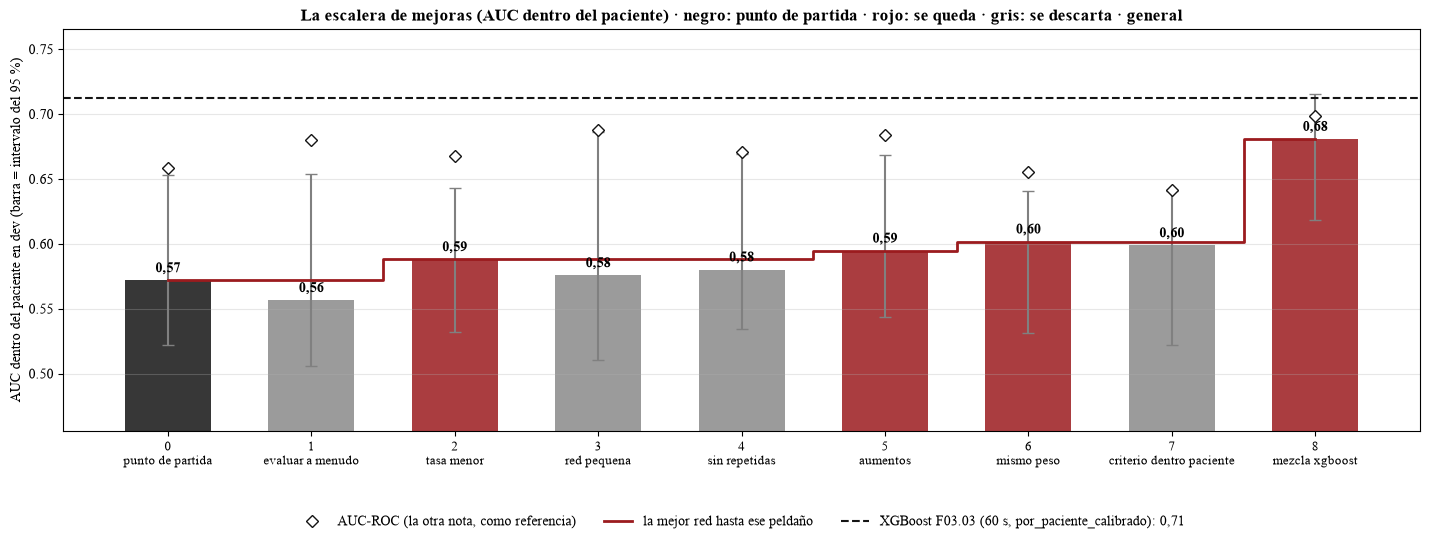

In [25]:
# 1) La nota de XGBoost y lo que se dibuja
auc_xgb = auroc_con_intervalo(y[comun], p_xgb[comun], pacientes[comun], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLAS[0])
notas_xgb = evaluador.notas(p_xgb)
nombres = [i.split(' · ', 1)[1] for i in escalera.index]
sufijo_ic = '_dentro' if METRICA_ESCALERA == 'dentro_paciente' else ''
OTRA = 'AUC-ROC' if NOTA != 'AUC-ROC' else 'AUC dentro del paciente'

# 2) Dibujar: una barra por peldaño, la mejor hasta ese peldaño y XGBoost
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(max(9, 1.6 * len(escalera)), 5.6))
    x = np.arange(len(escalera))
    colores = [COLORES_ESQUEMA['negro'] if d == 'punto de partida' else COLORES_ESQUEMA['rojo'] if d.startswith('✅') else COLORES_ESQUEMA['gris']
               for d in escalera['decisión']]
    ax.bar(x, escalera[NOTA], color=colores, alpha=0.85, width=0.6)
    ax.errorbar(x, escalera[NOTA], yerr=[escalera[NOTA] - escalera['_inferior' + sufijo_ic], escalera['_superior' + sufijo_ic] - escalera[NOTA]],
                fmt='none', ecolor='gray', capsize=4)
    ax.plot(x, escalera[OTRA], 'D', color=COLORES_ESQUEMA['negro'], ms=6, mfc='white', label=f'{OTRA} (la otra nota, como referencia)')
    mejor_hasta = np.maximum.accumulate(np.where([d != '✖️ se descarta' for d in escalera['decisión']], escalera[NOTA], -np.inf))
    ax.step(x, mejor_hasta, where='mid', color=COLORES_ESQUEMA['rojo'], lw=2, label='la mejor red hasta ese peldaño')
    ax.axhline(notas_xgb[NOTA], color=COLORES_ESQUEMA['negro'], ls='--', lw=1.5, label=f'{NOMBRE_XGB}: {decimal(notas_xgb[NOTA])}')
    for xi, auc in enumerate(escalera[NOTA]):
        ax.text(xi, auc + 0.004, decimal(auc), ha='center', va='bottom', fontsize=10, fontweight='bold')

    # 3) Rotular y guardar
    ax.set_xticks(x, [f'{i}\n{n.replace("_", " ")}' for i, n in enumerate(nombres)], fontsize=9.5)
    abajo = min(escalera['_inferior' + sufijo_ic].min(), escalera[OTRA].min(), notas_xgb[NOTA])
    arriba = max(escalera['_superior' + sufijo_ic].max(), escalera[OTRA].max(), notas_xgb[NOTA])
    ax.set_ylim(max(0.4, abajo - 0.05), min(1.06, arriba + 0.05))
    ax.set_ylabel(f'{NOTA} en dev (barra = intervalo del 95 %)')
    ax.set_title(f'La escalera de mejoras ({NOTA}) · negro: punto de partida · rojo: se queda · gris: se descarta · {CONJUNTO}', fontsize=12, fontweight='bold')
    ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3)
    ax.grid(alpha=0.3, axis='y')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'escalera.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Una barra por peldaño, en orden (la etiqueta lleva su número y su nombre), con la nota que usa la escalera y su intervalo del 95 %. Negro: el punto de partida; rojo: cambios que se quedan; gris: descartados. Los rombos blancos son la otra nota (si la escalera decide dentro del paciente, la global). La línea roja escalonada es **la mejor red hasta ese momento**; la discontinua negra, XGBoost de F03.03 con la misma nota.

✅ **Qué deberías ver:** la línea roja subiendo peldaño a peldaño hacia (o por encima de) la negra. Si los intervalos se solapan mucho entre peldaños, cada paso por separado es pequeño; lo que se mide en serio es el final frente al punto de partida y frente a XGBoost (§8).

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_FIGURAS</code> · carpeta <code>figuras/</code> dentro de la de salida <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">escalera</code> · la nota de cada peldaño <i style="color:#4d4d4d">(§6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">historiales</code> · curvas de aprendizaje de cada peldaño <i style="color:#4d4d4d">(§6)</i></li></ul></div>

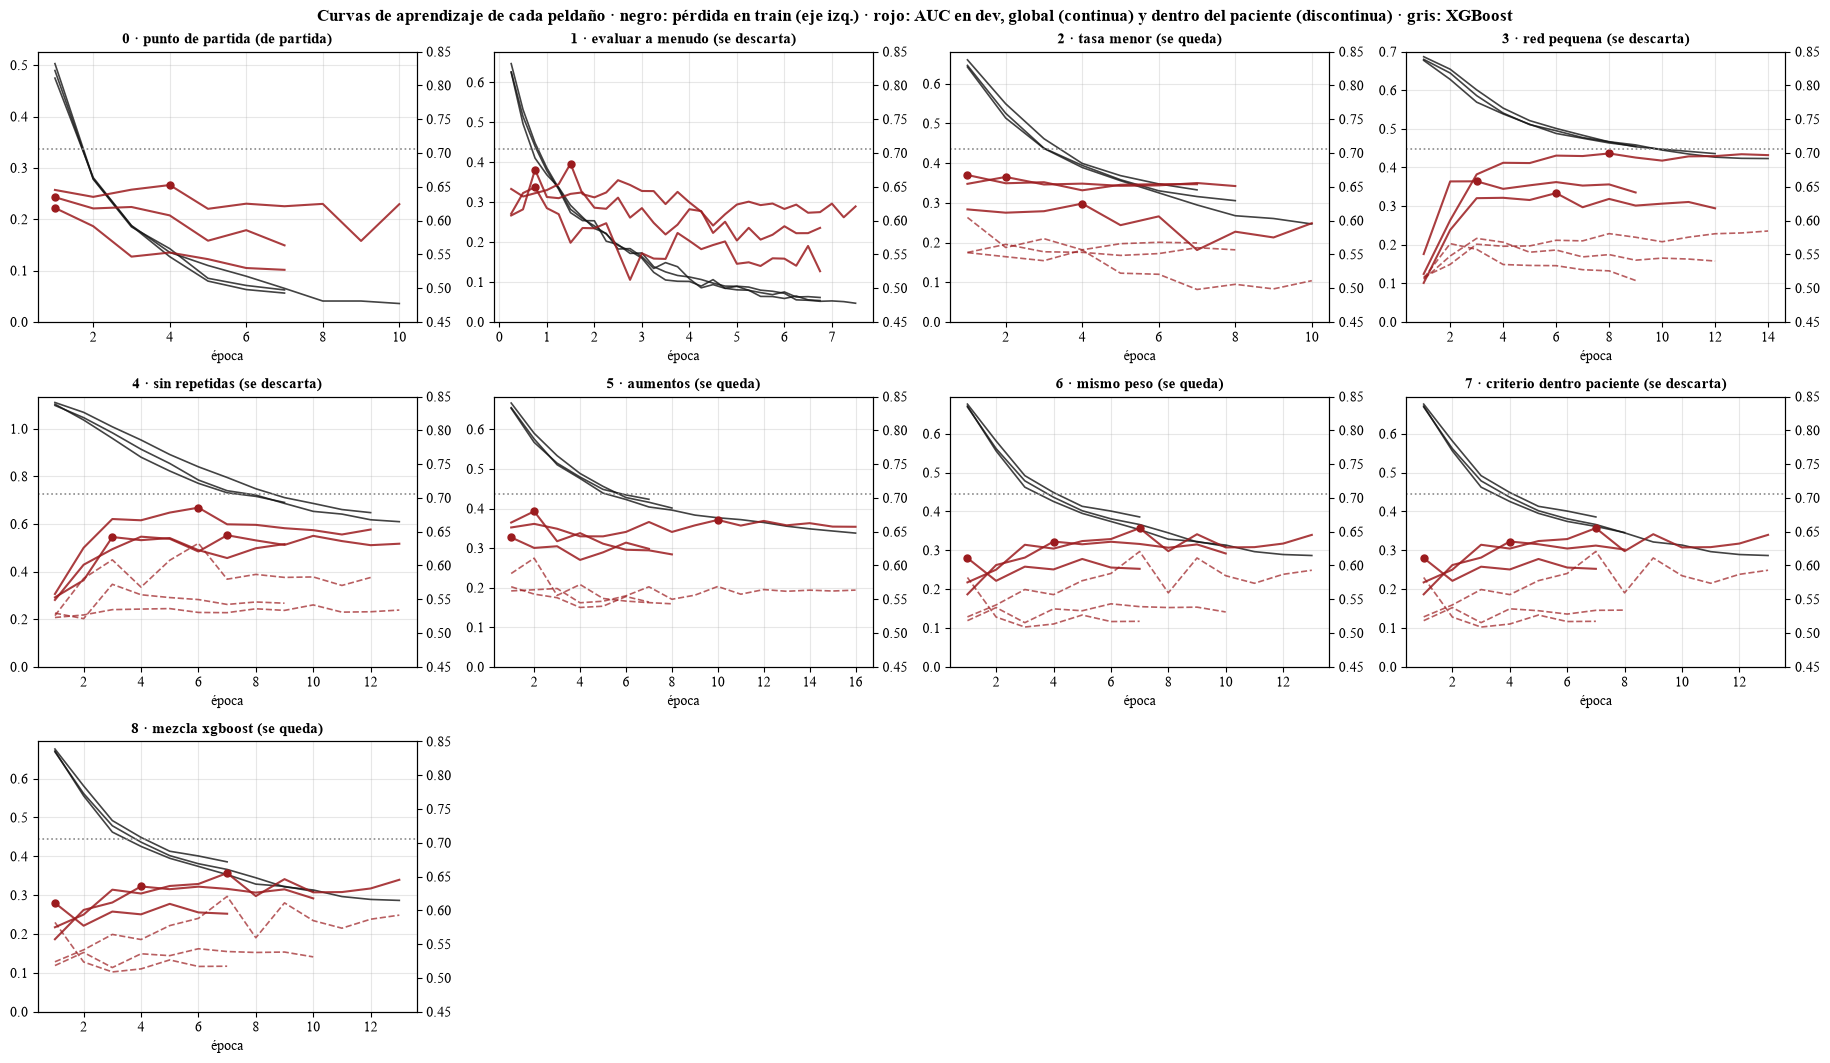

In [26]:
# 1) Una rejilla de paneles, uno por peldaño
n = len(historiales)
columnas = min(4, n)
filas_fig = int(np.ceil(n / columnas))

# 2) Dibujar las curvas de cada peldaño
with plt.rc_context(ESTILO_TIMES):
    fig, axes = plt.subplots(filas_fig, columnas, figsize=(4.6 * columnas, 3.6 * filas_fig), squeeze=False)
    for ax, (i, (nombre, h)) in zip(axes.flat, enumerate(historiales.items())):
        ax2 = ax.twinx()
        for _, hs in h.groupby(['semilla', 'ronda']):
            ax.plot(hs['época'], hs['pérdida train'], color=COLORES_ESQUEMA['negro'], lw=1.2, alpha=0.8)
            ax2.plot(hs['época'], hs['AUC validación'], color=COLORES_ESQUEMA['rojo'], lw=1.5, alpha=0.85)
            if 'AUC dentro paciente' in hs and hs['AUC dentro paciente'].notna().any():
                ax2.plot(hs['época'], hs['AUC dentro paciente'], color=COLORES_ESQUEMA['rojo'], lw=1.2, ls='--', alpha=0.7)
            m = hs.loc[hs['AUC validación'].idxmax()]
            ax2.plot(m['época'], m['AUC validación'], 'o', color=COLORES_ESQUEMA['rojo'], ms=5)
        ax2.axhline(auc_xgb[0], color=COLORES_ESQUEMA['gris'], ls=':', lw=1.2)
        ax.set_title(f'{i} · {nombre.replace("_", " ")} ({escalera.iloc[i]["decisión"].split(" ", 1)[-1]})', fontsize=10.5, fontweight='bold')
        ax.set_xlabel('época')
        ax.grid(alpha=0.3)
        ax.set_ylim(bottom=0)
        ax2.set_ylim(0.45, 0.85)

    # 3) Apagar los paneles sobrantes, título y guardar
    for ax in list(axes.flat)[n:]:
        ax.axis('off')
    fig.suptitle('Curvas de aprendizaje de cada peldaño · negro: pérdida en train (eje izq.) · rojo: AUC en dev, global (continua) y dentro del paciente (discontinua) · gris: XGBoost',
                 fontsize=12, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'curvas_por_peldano.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Un panel por peldaño, con una línea por semilla. Negro: la pérdida en train (cuánto se equivoca en los ejemplos que ve). Rojo continuo: la AUC global en dev, con un punto en su mejor momento; rojo discontinuo: la AUC dentro del paciente (solo en los peldaños entrenados desde que existe). Gris de puntos: XGBoost (global). La mezcla con XGBoost no se entrena: repite las curvas de la red de la que sale.

✅ **Qué deberías ver:** en el punto de partida, el negro cayendo en picado y el rojo bajando desde el principio (sobreajuste). En los peldaños que ayudan, el negro baja **más despacio** y el rojo sube durante más tiempo antes de estancarse.

## 8. La mejor red frente a XGBoost (y frente al punto de partida)

> 🎯 **Qué hacemos:** comparar la mejor red de la escalera con XGBoost de F03.03 y con el punto de partida, con diferencia emparejada.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MEJORA_MINIMA</code> · mejora mínima de AUC para dar por buena una mejora <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code> · <code>True</code> = prueba rápida (pocas ventanas, 1 semilla); las cifras no valen <i style="color:#4d4d4d">(§0)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_XGB</code> · nombre de la referencia XGBoost <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOTA</code> · nombre de esa nota en las tablas <i style="color:#4d4d4d">(§6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">actual</code> · la mejor red hasta ahora <i style="color:#4d4d4d">(§6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">diferencia</code> · función: diferencia emparejada entre dos redes <i style="color:#4d4d4d">(§6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">escalera</code> · la nota de cada peldaño <i style="color:#4d4d4d">(§6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">evaluador</code> · calcula todas las notas con las mismas ventanas <i style="color:#4d4d4d">(§6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_xgb</code> · notas de XGBoost (F03.03) <i style="color:#4d4d4d">(§7)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_xgb</code> · puntuación de XGBoost de F03.03 en cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones</code> · puntuación de cada ventana de dev, por peldaño <i style="color:#4d4d4d">(§6)</i></li></ul></div>

In [27]:
# 1) La mejor red frente al punto de partida y frente a XGBoost
p_mejor = actual['p']
nombre_mejor = actual['nombre']
d_xgb = diferencia(p_mejor, p_xgb)
d_base = diferencia(p_mejor, puntuaciones['punto_de_partida'])
d_xgb_global = evaluador.diferencia(p_mejor, p_xgb, dentro=False)
d_xgb_dentro = evaluador.diferencia(p_mejor, p_xgb, dentro=True)

# 2) Tabla de comparaciones
comparacion = pd.DataFrame([
    {'pregunta': f'¿ha mejorado la escalera la red de F03.04? ({NOTA})', 'A': nombre_mejor, 'B': 'punto de partida',
     'diferencia (A − B)': con_signo(d_base[0]), 'IC 95 %': f'{decimal(d_base[1], 3)} – {decimal(d_base[2], 3)}', 'lectura': lectura_diferencia(d_base, MEJORA_MINIMA)},
    {'pregunta': '¿supera a XGBoost DENTRO del paciente?', 'A': nombre_mejor, 'B': NOMBRE_XGB,
     'diferencia (A − B)': con_signo(d_xgb_dentro[0]), 'IC 95 %': f'{decimal(d_xgb_dentro[1], 3)} – {decimal(d_xgb_dentro[2], 3)}', 'lectura': lectura_diferencia(d_xgb_dentro, MEJORA_MINIMA)},
    {'pregunta': '¿supera a XGBoost en la nota GLOBAL?', 'A': nombre_mejor, 'B': NOMBRE_XGB,
     'diferencia (A − B)': con_signo(d_xgb_global[0]), 'IC 95 %': f'{decimal(d_xgb_global[1], 3)} – {decimal(d_xgb_global[2], 3)}', 'lectura': lectura_diferencia(d_xgb_global, MEJORA_MINIMA)},
]).set_index('pregunta')

# 3) El veredicto
notas_mejor = evaluador.notas(p_mejor)
if d_xgb[1] > 0 and d_xgb[0] >= MEJORA_MINIMA:
    veredicto = ('✅ La mejor de la escalera supera a XGBoost', 'la red pasa a ser el modelo de referencia de la fase')
elif d_xgb[2] < 0:
    veredicto = ('🔴 La mejor de la escalera sigue por debajo de XGBoost', 'los cambios probados no bastan: hay que probar otros peldaños (§5)')
else:
    veredicto = ('🟡 Sin diferencia clara con XGBoost', f'la red queda {"por encima" if d_xgb[0] > 0 else "por debajo"} ({con_signo(d_xgb[0])}), '
                 'pero el intervalo incluye el 0: con estos pacientes no se puede decir cuál es mejor')
if MODO_PRUEBA:
    veredicto = ('🔴 MODO PRUEBA · ' + veredicto[0], veredicto[1] + ' (cifras sin valor)')

# 4) Las dos notas de los tres modelos
cambios_que_quedan = [f'{i.split(" · ", 1)[1]} ({escalera.loc[i, "cambio"]})' for i in escalera.index[escalera['decisión'].str.startswith('✅')]]
notas_base = escalera.iloc[0]
tabla_notas = pd.DataFrame({
    'dentro del paciente': [con_intervalo(notas_mejor['AUC dentro del paciente'], notas_mejor['_inferior_dentro'], notas_mejor['_superior_dentro']),
                            decimal(notas_base['AUC dentro del paciente']),
                            con_intervalo(notas_xgb['AUC dentro del paciente'], notas_xgb['_inferior_dentro'], notas_xgb['_superior_dentro'])],
    'global': [con_intervalo(notas_mejor['AUC-ROC'], notas_mejor['_inferior'], notas_mejor['_superior']), decimal(notas_base['AUC-ROC']),
               con_intervalo(notas_xgb['AUC-ROC'], notas_xgb['_inferior'], notas_xgb['_superior'])]},
    index=pd.Index([f'mejor de la escalera ({nombre_mejor})', 'punto de partida (F03.04)', NOMBRE_XGB], name='AUC en 🟡 dev'))

# 5) Mostrarlo destacado
mostrar_destacado(veredicto[0] + f' ({NOTA})',
                  f'La escalera decide con la <b>{NOTA}</b>. Las dos notas de los tres modelos:', tabla_notas,
                  comparacion,
                  '<b>Cambios que se han quedado:</b> ' + ('; '.join(cambios_que_quedan) if cambios_que_quedan else 'ninguno') + '.',
                  f'<b>Qué significa:</b> {veredicto[1]}.')

👀 **Cómo leer el recuadro.** Arriba, el veredicto y las tres notas (la mejor red, el punto de partida y XGBoost). La tabla responde a las dos preguntas con diferencia emparejada: si el intervalo no incluye el 0, la diferencia es real. Abajo, qué cambios se han quedado en la mejor red.

✅ **Qué deberías ver:** que la escalera mejora al punto de partida y si eso basta para alcanzar a XGBoost.

## 9. Por paciente, por grupo y control de sesión

> 🎯 **Qué hacemos:** mirar la mejor red por paciente, por grupo de inicio y en el control de sesión.
>
> 🤔 **Por qué:** una mejora global puede esconder pacientes que empeoran, o apoyarse en la grabación.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comun</code> · ventanas de dev que tienen nota de todos los modelos <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · ventanas del estudio (las de F03.03, con contexto completo) <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_mejor</code> · puntuación de la mejor red en cada ventana <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_xgb</code> · puntuación de XGBoost de F03.03 en cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones</code> · puntuación de cada ventana de dev, por peldaño <i style="color:#4d4d4d">(§6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · etiqueta de cada ventana (1 = ⏳ preictal) <i style="color:#4d4d4d">(§3)</i></li></ul></div>

In [ ]:
# 1) AUC dentro de cada paciente con la mejor red, el punto de partida y XGBoost
pp_red = auroc_por_paciente(y[comun], p_mejor[comun], pacientes[comun])
pp_xgb = auroc_por_paciente(y[comun], p_xgb[comun], pacientes[comun])
pp_base = auroc_por_paciente(y[comun], puntuaciones['punto_de_partida'][comun], pacientes[comun])
por_paciente = (pp_red[['auroc', '⏳ preictal', '💤 interictal']].rename(columns={'auroc': 'AUC mejor red'})
                .join(pp_base[['auroc']].rename(columns={'auroc': 'AUC punto de partida'}))
                .join(pp_xgb[['auroc']].rename(columns={'auroc': 'AUC XGBoost'})))

# 2) Resumen paciente a paciente
resumen_pacientes = pd.DataFrame({m: {'mediana de la AUC por paciente': por_paciente[f'AUC {m}'].median(),
                                      'pacientes por encima del azar': int((por_paciente[f'AUC {m}'] > 0.5).sum()),
                                      'pacientes en los que gana a XGBoost': int((por_paciente[f'AUC {m}'] > por_paciente['AUC XGBoost']).sum()) if m != 'XGBoost' else np.nan}
                                  for m in ['mejor red', 'punto de partida', 'XGBoost']}).T
resumen_pacientes.index.name = f'modelo ({len(por_paciente)} pacientes de dev)'
display(Markdown('**Paciente a paciente**'))
display(con_separadores(resumen_pacientes, decimales=3))

# 3) Por grupo de inicio
grupos = [g for g in ['focal', 'generalizada', 'ausencia'] if g in set(filas.grupo[comun & (y == 1)].dropna())]
filas_grupo = {}
for g in grupos:
    m = comun & ((y == 0) | (filas.grupo.to_numpy() == g))
    fila = {'pacientes con ⏳': len(set(pacientes[m & (y == 1)]))}
    for etiqueta, p in [('mejor red', p_mejor), ('punto de partida', puntuaciones['punto_de_partida']), ('XGBoost', p_xgb)]:
        fila[f'AUC {etiqueta}'] = auroc_con_intervalo(y[m], p[m], pacientes[m], n_bootstrap=1)[0]
    filas_grupo[con_icono(g)] = fila
por_grupo = pd.DataFrame(filas_grupo).T.infer_objects()
por_grupo.index.name = 'grupo de inicio'
display(Markdown('**Por grupo de inicio** (⏳ de ese grupo frente a todas las 💤)'))
display(con_separadores(por_grupo, decimales=3))

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP</code> · repeticiones del bootstrap por paciente <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLAS</code> · semillas con las que se entrena cada peldaño <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comun</code> · ventanas de dev que tienen nota de todos los modelos <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · ventanas del estudio (las de F03.03, con contexto completo) <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_mejor</code> · notas de la mejor red <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_mejor</code> · puntuación de la mejor red en cada ventana <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_xgb</code> · puntuación de XGBoost de F03.03 en cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones</code> · puntuación de cada ventana de dev, por peldaño <i style="color:#4d4d4d">(§6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · etiqueta de cada ventana (1 = ⏳ preictal) <i style="color:#4d4d4d">(§3)</i></li></ul></div>

In [ ]:
# 1) Los controles de sesión y la nota de cada modelo en cada uno
controles = controles_de_sesion(comun, y, pacientes, filas.file.to_numpy())
filas_control = {}
for nombre_control, m in controles.items():
    if (y[m] == 0).sum() == 0 or (y[m] == 1).sum() == 0:
        continue
    fila = {'💤 interictal': int((y[m] == 0).sum())}
    for etiqueta, p in [('mejor red', p_mejor), ('punto de partida', puntuaciones['punto_de_partida']), ('XGBoost', p_xgb)]:
        a, i_, s_ = auroc_con_intervalo(y[m], p[m], pacientes[m], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLAS[0])
        fila[f'AUC {etiqueta}'], fila[f'IC {etiqueta}'] = a, f'{decimal(i_)} – {decimal(s_)}'
    filas_control[nombre_control] = fila

# 2) Tabla
control_sesion = pd.DataFrame(filas_control).T.infer_objects()
control_sesion.index.name = 'qué 💤 se usan'
display(Markdown('**Control de sesión** (F03.03 §10)'))
display(con_separadores(control_sesion, decimales=3))

# 3) Veredicto de la mejor red
auc_ses = control_sesion.loc['misma sesión', 'AUC mejor red'] if 'misma sesión' in control_sesion.index else np.nan
veredicto_sesion = ('✅ Se mantiene' if auc_ses >= notas_mejor['AUC-ROC'] - 0.05 else '🟡 Baja en la misma sesión') if not np.isnan(auc_ses) else '— sin control'
print(f'Control de sesión de la mejor red: {veredicto_sesion} (misma sesión: {decimal(auc_ses)} · todas: {decimal(notas_mejor["AUC-ROC"])})')

👀 **Cómo leer las tablas.** Las tres comparan la mejor red, el punto de partida (F03.04) y XGBoost. **Paciente a paciente:** la mediana de la AUC dentro de cada paciente, en cuántos supera el azar y en cuántos gana a XGBoost. **Por grupo:** la AUC con las ⏳ de cada grupo de inicio. **Control de sesión:** la AUC con todas las 💤, con las de la misma sesión y con las del mismo fichero.

✅ **Qué deberías ver:** que la mejora no se queda en la cifra global: la mediana por paciente también sube y la nota aguanta con las 💤 de la misma sesión. Recuerda que en F03.04 la variante de mismo peso subía la AUC global pero bajaba la mediana por paciente: si el peldaño `mismo_peso` se queda, mira esta tabla con cuidado.

## 10. El resultado → ficheros

> 🎯 **Qué hacemos:** guardar la escalera, las puntuaciones y `configuracion.json`.
>
> 🤔 **Por qué:** F03.06-F03.08 se comparan con la mejor red de aquí.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_RESULTADOS</code> · carpeta de salida de este notebook (en <code>outputs/</code>) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">comun</code> · ventanas de dev que tienen nota de todos los modelos <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">control_sesion</code> · tabla del control de sesión <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">escalera</code> · la nota de cada peldaño <i style="color:#4d4d4d">(§6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · ventanas del estudio (las de F03.03, con contexto completo) <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_xgb</code> · puntuación de XGBoost de F03.03 en cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">por_paciente</code> · AUC de cada paciente, red y XGBoost <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones</code> · puntuación de cada ventana de dev, por peldaño <i style="color:#4d4d4d">(§6)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">registro</code> · registro de experimentos: lo ya entrenado no se repite <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [ ]:
# 1) La escalera y el registro de experimentos
guardar = (escalera.drop(columns=['_inferior', '_superior'])
           .assign(ic_inferior=escalera._inferior, ic_superior=escalera._superior)
           .reset_index())
guardar.to_csv(RUTA_RESULTADOS / 'escalera.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'escalera.csv', 'una fila por peldaño de esta ejecución: el cambio, la AUC en 🟡 dev, la diferencia con la mejor hasta ahora y la decisión')
mostrar_fichero(registro.ruta, 'el registro de TODOS los experimentos hechos con este notebook (también los de ejecuciones anteriores): huella, nota y configuración')

# 2) Las puntuaciones de cada ventana de dev
puntos = filas.loc[comun, ['id_ventana', 'split', 'patient', 'file', 'clase', 'etiqueta', 'grupo', 'crisis_id']].copy()
for nombre, p in puntuaciones.items():
    puntos[f'puntuacion_{nombre}'] = p[comun].round(5)
puntos['puntuacion_xgboost_f0303'] = p_xgb[comun].round(5)
puntos.to_csv(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', 'una fila por ventana de 🟡 dev: la probabilidad de ⏳ de cada peldaño (media de las semillas) y la de XGBoost')

# 3) Control de sesión y AUC por paciente
control_sesion.reset_index().to_csv(RUTA_RESULTADOS / 'control_sesion.csv', index=False)
por_paciente.reset_index().to_csv(RUTA_RESULTADOS / 'auc_por_paciente.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'auc_por_paciente.csv', 'una fila por paciente de 🟡 dev: AUC dentro del paciente con la mejor red, el punto de partida y XGBoost')

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§0:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§1:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">versiones_usadas</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§2:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MEJORA_PELDANO</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">METRICA_ESCALERA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRE_XGB</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_MODELOS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">RUTA_RESULTADOS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLAS</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">config_04</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">ficha</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§5:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">PELDANOS</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§6:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOTA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">actual</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_base</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">columnas_ver</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">escalera</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§7:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_xgb</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_xgb</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§8:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_base</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_xgb_dentro</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_xgb_global</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">nombre_mejor</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_mejor</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§9:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">control_sesion</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">por_grupo</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resumen_pacientes</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto_sesion</code></li></ul></div>

In [ ]:
# 1) configuracion.json: la escalera, la mejor red, sus notas y sus modelos
config = {
    'conjunto': CONJUNTO, 'modo_prueba': MODO_PRUEBA, 'eval_usado': False, 'semillas': SEMILLAS, 'mejora_peldano': MEJORA_PELDANO,
    'peldanos': [{'nombre': n, 'cambio': c, 'por_que': p} for n, c, p in PELDANOS],
    'mejor': {'nombre': nombre_mejor, 'huella': actual['huella'], 'configuracion': actual['config'], 'auc_dev': float(notas_mejor['AUC-ROC']),
              'auc_dentro_paciente_dev': float(notas_mejor['AUC dentro del paciente']),
              'usa_xgboost': bool(actual['config'].get('mezclar_xgboost', False)),
              'ic95_dev': [float(notas_mejor['_inferior']), float(notas_mejor['_superior'])],
              'modelos': sorted(str(r.relative_to(RUTA_RESULTADOS)).replace('\\', '/') for r in RUTA_MODELOS.glob(f'{actual["huella"]}_semilla*.pt'))},
    'punto_de_partida': {'auc_dev': float(auc_base), 'auc_dev_f0304': config_04['principal']['auc_dev']},
    'metrica_escalera': METRICA_ESCALERA,
    'frente_a_xgboost': {'auc_xgboost': float(auc_xgb[0]), 'auc_dentro_xgboost': float(notas_xgb['AUC dentro del paciente']),
                         'diferencia_global': float(d_xgb_global[0]), 'ic95_global': [float(d_xgb_global[1]), float(d_xgb_global[2])],
                         'diferencia_dentro': float(d_xgb_dentro[0]), 'ic95_dentro': [float(d_xgb_dentro[1]), float(d_xgb_dentro[2])],
                         'veredicto': veredicto[0]},
    'frente_al_punto_de_partida': {'diferencia': float(d_base[0]), 'ic95_diferencia': [float(d_base[1]), float(d_base[2])]},
    'control_sesion': veredicto_sesion, 'dispositivo': ficha['dispositivo'], 'versiones': versiones_usadas, 'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
(RUTA_RESULTADOS / 'configuracion.json').write_text(json.dumps(config, indent=4, ensure_ascii=False, default=str), encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json', 'la escalera, la configuración de la mejor red, sus notas y dónde están sus modelos')

# 2) summary.txt: el resumen en texto
texto = ('=== F03.05 · La escalera de mejoras de la red ===\n'
         + f'{config["fecha"]} · conjunto {CONJUNTO} · semillas {SEMILLAS}' + (' · MODO PRUEBA' if MODO_PRUEBA else '') + '\n'
         + f'Punto de partida: AUC {decimal(auc_base)} · mejor ({nombre_mejor}): AUC {con_intervalo(notas_mejor["AUC-ROC"], notas_mejor["_inferior"], notas_mejor["_superior"])} · '
         + f'{NOMBRE_XGB}: {decimal(auc_xgb[0])}\n'
         + f'La escalera decide con: {NOTA} · mejor dentro del paciente: {decimal(notas_mejor["AUC dentro del paciente"])} (XGBoost {decimal(notas_xgb["AUC dentro del paciente"])})\n'
         + f'Frente a XGBoost: {veredicto[0]} · dentro {con_signo(d_xgb_dentro[0])} (IC {decimal(d_xgb_dentro[1], 3)} – {decimal(d_xgb_dentro[2], 3)}) · '
         + f'global {con_signo(d_xgb_global[0])} (IC {decimal(d_xgb_global[1], 3)} – {decimal(d_xgb_global[2], 3)})\n'
         + f'Frente al punto de partida: {con_signo(d_base[0])} (IC {decimal(d_base[1], 3)} – {decimal(d_base[2], 3)})\n'
         + f'Control de sesión: {veredicto_sesion}\n\n'
         + '--- Escalera ---\n' + escalera[columnas_ver].round(3).to_string() + '\n\n'
         + '--- Paciente a paciente ---\n' + resumen_pacientes.round(3).to_string() + '\n\n'
         + '--- Por grupo ---\n' + por_grupo.round(3).to_string() + '\n\n'
         + '--- Control de sesión ---\n' + control_sesion.round(3).to_string() + '\n')
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'summary.txt', 'el resumen de la escalera en texto')

## 11. Conclusiones

> 🎯 **Qué hacemos:** escribir las conclusiones con los datos de esta ejecución.
>
> 🤔 **Por qué:** si cambian los peldaños o los datos, cambian solas.

Se escriben solas a partir de los datos al ejecutar la celda.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§0:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODO_PRUEBA</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§2:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MEJORA_MINIMA</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§6:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOTA</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">escalera</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§7:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">nombres</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§8:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_base</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_xgb_dentro</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">d_xgb_global</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">nombre_mejor</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">notas_mejor</code></li><li style="color:#1a1a1a; margin:2px 0"><i style="color:#4d4d4d">§9:</i> <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_ses</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">resumen_pacientes</code>, <code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">veredicto_sesion</code></li></ul></div>

In [30]:
# 1) Las conclusiones, escritas solas a partir de los datos
conclusiones = []
if MODO_PRUEBA:
    conclusiones.append('🔴 **MODO PRUEBA:** con un 10 % de las ventanas, 1 semilla y 2 épocas, estas cifras no tienen valor.')
conclusiones.append(f'**1. La escalera ({NOTA}).** De {decimal(escalera.iloc[0][NOTA])} (punto de partida) a **{decimal(notas_mejor[NOTA])}** ({nombre_mejor}): '
                    f'{con_signo(d_base[0])} (IC {decimal(d_base[1], 3)} – {decimal(d_base[2], 3)}), {lectura_diferencia(d_base, MEJORA_MINIMA)}.')
for indice, fila in escalera.iloc[1:].iterrows():
    conclusiones.append(f'- **{indice}** ({fila["cambio"]}): {decimal(fila[NOTA])} frente a {fila["se prueba sobre"]} '
                        f'({fila["frente a la mejor hasta ahora"]}) → {fila["decisión"]}; mejor época media {decimal(fila["mejor época (media)"], 1)}.')
conclusiones.append(f'**2. Frente a XGBoost.** Dentro del paciente: {con_signo(d_xgb_dentro[0])} (IC {decimal(d_xgb_dentro[1], 3)} – {decimal(d_xgb_dentro[2], 3)}), '
                    f'{lectura_diferencia(d_xgb_dentro, MEJORA_MINIMA)}. Global: {con_signo(d_xgb_global[0])} (IC {decimal(d_xgb_global[1], 3)} – {decimal(d_xgb_global[2], 3)}), {lectura_diferencia(d_xgb_global, MEJORA_MINIMA)}.'
                    + (' La red gana fuera pero no dentro: parte de su nota global viene de separar pacientes.' if d_xgb_global[0] > 0 > d_xgb_dentro[0] else ''))
conclusiones.append(f'**3. Sobreajuste.** La mejor época pasa de {decimal(escalera.iloc[0]["mejor época (media)"], 1)} (punto de partida) a '
                    f'{decimal(escalera.loc[escalera.index[[n == nombre_mejor for n in nombres]][0], "mejor época (media)"], 1)} en la mejor red'
                    + (': la red tarda más en memorizar.' if escalera.loc[escalera.index[[n == nombre_mejor for n in nombres]][0], 'mejor época (media)']
                       > escalera.iloc[0]['mejor época (media)'] else ': sigue sobreajustándose igual de deprisa.'))
conclusiones.append(f'**4. Por paciente.** Mediana de la AUC dentro de cada paciente: {decimal(resumen_pacientes.loc["mejor red", "mediana de la AUC por paciente"])} '
                    f'(punto de partida {decimal(resumen_pacientes.loc["punto de partida", "mediana de la AUC por paciente"])}, '
                    f'XGBoost {decimal(resumen_pacientes.loc["XGBoost", "mediana de la AUC por paciente"])}).')
conclusiones.append(f'**5. Control de sesión:** {veredicto_sesion} (misma sesión {decimal(auc_ses)}).')

# 2) Mostrar
display(Markdown('\n\n'.join(conclusiones)))

**1. La escalera (AUC dentro del paciente).** De 0,57 (punto de partida) a **0,68** (mezcla_xgboost): +0,109 (IC -0,015 – 0,177), sin diferencia clara (el intervalo incluye el 0).

- **1 · evaluar_a_menudo** (evaluaciones_por_epoca = 4): 0,56 frente a punto_de_partida (-0,015 [-0,029 – 0,016]) → ✖️ se descarta; mejor época media 1,0.

- **2 · tasa_menor** (lr = 0.0001): 0,59 frente a punto_de_partida (+0,016 [-0,035 – 0,048]) → ✅ se queda; mejor época media 2,3.

- **3 · red_pequena** (filtros = 16 · resumen_ventana = 32 · memoria_gru = 32 · dropout = 0.5): 0,58 frente a tasa_menor (-0,012 [-0,064 – 0,070]) → ✖️ se descarta; mejor época media 5,7.

- **4 · sin_repetidas** (separacion_s = 16 · equilibrar_clases = True · epocas_max = 80): 0,58 frente a tasa_menor (-0,008 [-0,036 – 0,044]) → ✖️ se descarta; mejor época media 5,3.

- **5 · aumentos** (apagar_canales = 0.1 · tapar_frecuencias = 4): 0,59 frente a tasa_menor (+0,007 [-0,010 – 0,037]) → ✅ se queda; mejor época media 4,3.

- **6 · mismo_peso** (mismo_peso = True): 0,60 frente a aumentos (+0,007 [-0,064 – 0,043]) → ✅ se queda; mejor época media 4,0.

- **7 · criterio_dentro_paciente** (criterio = auc_dentro_paciente): 0,60 frente a mismo_peso (-0,003 [-0,014 – 0,004]) → ✖️ se descarta; mejor época media 3,3.

- **8 · mezcla_xgboost** (mezclar_xgboost = True): 0,68 frente a mismo_peso (+0,079 [0,029 – 0,148]) → ✅ se queda; mejor época media 4,0.

**2. Frente a XGBoost.** Dentro del paciente: -0,031 (IC -0,067 – 0,011), sin diferencia clara (el intervalo incluye el 0). Global: -0,007 (IC -0,035 – 0,018), sin diferencia clara (el intervalo incluye el 0).

**3. Sobreajuste.** La mejor época pasa de 2,0 (punto de partida) a 4,0 en la mejor red: la red tarda más en memorizar.

**4. Por paciente.** Mediana de la AUC dentro de cada paciente: 0,69 (punto de partida 0,67, XGBoost 0,71).

**5. Control de sesión:** ✅ Se mantiene (misma sesión 0,71).

## 12. Cómo seguir

> 🎯 **Qué hacemos:** dejar apuntadas las ideas para seguir subiendo la escalera.
>
> 🤔 **Por qué:** añadir un peldaño es una línea en `PELDANOS`; el registro hace el resto.

- **Probar algo nuevo:** añade un peldaño al final de `PELDANOS` (§5) y vuelve a ejecutar. Ideas, de más sencilla a más trabajo:
  - `weight_decay` más alto (0,05) o `dropout` 0,6;
  - `separacion_s` mayor (32 s) si el peldaño `sin_repetidas` ayudó;
  - cambiar la GRU por una LSTM o un Transformer pequeño (un fichero nuevo en `tfm_comun/red/redes/` y una línea en `REDES` de `tfm_comun/red/modelo.py`);
  - la señal en bruto con una CNN tipo EEGNet, o la red de grafos de Tang et al. (notebooks aparte, comparados con la mejor red de aquí).
- **Ojo con el número de pruebas:** cada decisión tomada con 🟡 dev la hace un poco más optimista. Por eso la evaluación final en 🟢 eval se hace **una sola vez** y al final de la fase, con la mejor red de este notebook (`configuracion.json` → `mejor`).

> 📝 **Para la memoria.** La escalera se cuenta sola con la figura de §7 y la tabla de §6: cada cambio, por qué se probó, cuánto movió la AUC y si se quedó. Es la forma honesta de explicar cómo se llegó a la red final, incluidos los cambios que **no** funcionaron.

## 13. Archivos generados

En `outputs/fase_03/05_mejoras_red/`:

- `escalera.csv`: los peldaños de esta ejecución y sus decisiones.
- `registro/`: **todos** los experimentos (`registro.csv`), sus puntuaciones (`puntuaciones/<huella>.npz`) y sus curvas (`historial/<huella>.csv`). No borrar: es lo que evita reentrenar.
- `modelos/<huella>_semilla<n>_<ronda>.pt`: los pesos de cada red, con su configuración.
- `puntuaciones_validacion.csv`, `auc_por_paciente.csv`, `control_sesion.csv`, `configuracion.json` y `summary.txt`.
- `figuras/`: `escalera.png` y `curvas_por_peldano.png`.